# Estimate Annual Generation for GM-SEUS Arrays (pvlib + TMY)
NOTE: Requires an environment with pvlib >= 0.12 (NSRDB PSM4 functions), geopandas, scipy, and pvcz (`pip install pvcz`). Run in the BigPanel environment (envFiles/BigPanel.yml), which has pvlib, pvcz, pyarrow, timezonefinder, and gmseusUtils.

This script models expected annual AC generation (MWh) for every GM-SEUS photovoltaic array from its installation year to 25 years after installation. Generation is modeled once per array with a Typical Meteorological Year (TMY) and a PVWatts-style _pvlib_ model chain. A temperature-zone performance loss rate (degradation) is then applied for each operating year. Because TMY is the same weather every year, operating year 1 is the undegraded TMY total and every later year differs only by degradation.

**Outputs**
* **GMSEUS_Generation_Annual_Wide**: `arrayID`, `genYr1` ... `genYr25` (MWh). For the GM-SEUS release.
* **GMSEUS_Generation_Annual_Long**: `arrayID`, `instYr`, `opYr`, `calYr`, `MWh`. For joining to other annual time series by calendar year.
* **GMSEUS_Generation_Shape12x24**: `arrayID` and 288 columns (`m01h00` ... `m12h23`) giving the share of a TMY year's energy produced in each month-by-hour cell (rows sum to 1). Used to weight time-varying quantities by when each array actually generates.
* **GMSEUS_Generation_ModelInputs**: the per-array model inputs actually used (mount, tilt, azimuth, axis, GCR, DC:AC ratio, temperature zone, PLR) with provenance columns, for auditing.

**Variables used**
* GM-SEUS: `arrayID`, `latitude`, `longitude`, `instYr`, `capMWDC`, `capMWAC`, `modType`, `mount`, `tilt`, `avgAzimuth`, `GCR2` (`Source` and `sourceConf` are carried through for auditing only).
* GM-SEUS panel-rows: `arrayID`, `rowAzimuth`, `rowLength`, `rowWidth` (used only to correct `avgAzimuth`).
* USPVDB: `p_cap_dc`, `p_cap_ac` (used only to derive the DC:AC check and fill value).
* Weather (hourly TMY): `ghi`, `dni`, `dhi`, `temp_air`, `wind_speed`, and `albedo` (NSRDB only; PVGIS uses `albedoDefault`).

**Weather**
* Option: NSRDB PSM4 TMY (NLR Developer Network, free API key) via `pvlib.iotools.get_nsrdb_psm4_tmy`, ~4 km grid. Arrays are snapped to weather cells so each cell is downloaded once and cached.
* Alternative: PVGIS TMY via `pvlib.iotools.get_pvgis_tmy` (no key, no daily cap; same source used for `tiltEst` in script8). PVGIS TMY has no albedo, so 0.2 is used.
* Set with `weatherSource` ('pvgis' default). Cache files, checkpoint, and outputs are named by source, so switching sources later requires no other changes.

**Degradation**
* Jordan, D. C., et al. (2022). Photovoltaic fleet degradation insights. Progress in Photovoltaics, 30, 1166-1175. Median PLR by PV temperature zone (T3: 0.48, T4: 0.78, T5: 0.88 %/year). Mount and module type were not differentiated because Jordan et al. found no statistically significant difference (p > 0.49).
* PV temperature zones from Karin et al. (2019) via the `pvcz` package (rack-mount, 1.1 eV equivalent temperature zone), the same zones used by Jordan et al.

**Key assumptions** (all set as variables in the first code cells; each setting's source is listed under Model Settings and Sources)
* Mount: `mixed*` arrays modeled as fixed-axis (conservative). `unknown` arrays assigned by a capacity cutoff derived from arrays with known fixed-axis vs single-axis mounts (balanced accuracy). `dual_axis` modeled as two-axis tracking.
* `capMWDC` used as-is. `capMWAC` sets inverter clipping; where the array's DC:AC ratio is outside the USPVDB 1st-99th percentile range (or AC is missing), AC is set to DC / USPVDB median DC:AC.
* Fixed-axis tilt from `tilt` (reported, gap-filled with `tiltEst` in script8). Only arrays newly assigned fixed-axis here (from `unknown`) can lack tilt; those are filled from a latitude regression fitted to fixed-axis `tilt`.
* Azimuth: `avgAzimuth` is first corrected from the panel-rows (see Azimuth Correction). Where it is missing, fixed-axis arrays face due south (180) and single-axis trackers have a north-south axis (axis azimuth 180, panels rotating east to west).
* Single-axis tracker axis azimuth from `avgAzimuth` (long-edge direction), horizontal axis, rotation limit of 45 degrees, with backtracking at `GCR2`. Fixed-axis row shading is not modeled (PVWatts-style), so GCR only affects trackers.
* `modType` sets the temperature coefficient only (PVWatts v8 Standard for c-Si, PVWatts v8 Thin film for all thin-film types).
* Total system losses (soiling, wiring, mismatch, availability, etc.) = `systemLosses` (PVWatts default 14%). Monofacial modules assumed (bifacial gain not modeled).
* Operating year 1 = `instYr`, treated as a full year of operation. Partial installation-year handling is left to downstream users.
* Linear degradation: MWh(opYr) = MWh_TMY x (1 - PLR x (opYr - 1)).
* 12x24 shape hours are labeled in each array's local standard time (its real time zone, no daylight saving), matching NSRDB and Cambium `timestamp_local`.
* CSP arrays (`modType` = csp) are not modeled and receive -9999.

# Import Libraries and Variables

In [47]:
# Import libraries
import os
import time
import warnings
import numpy as np
import pandas as pd
import geopandas as gpd
import pvlib
import pvcz
from scipy.spatial import cKDTree
from datetime import datetime
from zoneinfo import ZoneInfo
from timezonefinder import TimezoneFinder
import gmseusUtils as gu

# Suppress specific warnings globally (e.g., DeprecationWarning, FutureWarning)
warnings.filterwarnings("ignore", category=DeprecationWarning)
warnings.filterwarnings("ignore", category=FutureWarning)

In [48]:
# Set folder paths
wd = r'S:\Users\stidjaco\R_files\BigPanel'
temp_path = r'F:\BigPanel_Cache'
downloaded_path = os.path.join(wd, r'Data\Downloaded')
derived_path = os.path.join(wd, r'Data\Derived')
derivedTemp_path = os.path.join(derived_path, r'intermediateProducts')
generation_path = os.path.join(derived_path, r'generation')

# Set final GM-SEUS v2.1 array path
gmseusArraysPath = os.path.join(downloaded_path, r'SolarDB\GMSEUS_v2_1\SHP\GMSEUS_Arrays_Final_2025_v2_1.shp')

# Set GM-SEUS panel-row path (used to correct avgAzimuth) and USPVDB path (used to derive DC:AC)
gmseusPanelsPath = os.path.join(downloaded_path, r'SolarDB\GMSEUS_v2_1\SHP\GMSEUS_Panels_Final_2025_v2_0.shp')
uspvdbPath = os.path.join(downloaded_path, r'SolarDB\USPVDB\uspvdb_v4_0_20260414.shp')

# Set weather cache folder (one parquet file per weather cell)
weatherCache_path = os.path.join(temp_path, r'Weather_Cache')

# Set weather source: 'pvgis' (PVGIS TMY, no key, no daily cap) or 'nsrdb' (NSRDB PSM4 TMY, free NLR API key, 5,000 requests/day)
# The source is added to every cache file, checkpoint, and output name, so runs with each source can coexist and be compared.
weatherSource = 'pvgis'

# Set output paths (suffixed by weather source). Release outputs are CSV; the checkpoint is an intermediate parquet file in derivedTemp_path.
genWide_path = os.path.join(generation_path, r'GMSEUS_Generation_Annual_Wide_' + weatherSource + '.csv')
genLong_path = os.path.join(generation_path, r'GMSEUS_Generation_Annual_Long_' + weatherSource + '.csv')
genShape_path = os.path.join(generation_path, r'GMSEUS_Generation_Shape12x24_' + weatherSource + '.csv')
genInputs_path = os.path.join(generation_path, r'GMSEUS_Generation_ModelInputs_' + weatherSource + '.csv')
genCheckpoint_path = os.path.join(derivedTemp_path, r'genCheckpoint_' + weatherSource + '.parquet')

# Set validation paths: LBNL Utility-Scale Solar 2026 data file (plant-level annual capacity factors from EIA-923 net generation; downloaded in the validation cell if missing)
lbnlUrl = 'https://emp.lbl.gov/sites/default/files/2026-10/Utility%20Scale%20Solar%202026%20Edition%20Datafile.xlsx'
lbnlPath = os.path.join(downloaded_path, r'SolarDB\LBNLUSS\Utility Scale Solar 2026 Edition Datafile.xlsx')
genValid_path = os.path.join(derivedTemp_path, r'GMSEUS_Generation_Validation_LBNL_' + weatherSource + '.csv')
figure_path = os.path.join(wd, r'Figures')

# Make output and cache folders if they do not exist
os.makedirs(generation_path, exist_ok=True)
os.makedirs(weatherCache_path, exist_ok=True)

## Model Settings and Sources
Each setting in the next cell, where its value comes from, and why it was picked. PVWatts v5 = Dobos (2014), *PVWatts Version 5 Manual*, NREL/TP-6A20-62641. PVWatts v8 = NREL PVWatts Version 8 module types.

| Setting | Value | Source | Why |
|---|---|---|---|
| `weatherCellDeg` | 0.1 deg | Our choice | About 11 km, roughly twice the native PVGIS-SARAH (~0.05 deg) and NSRDB (~4 km) grids. Cuts downloads about 4x; TMY irradiance changes little at this scale, and solar geometry still uses each array's own location. |
| `apiPauseSec` | NSRDB 1.5 s, PVGIS 0.2 s | NSRDB: 1 request/s limit (NLR Developer Network). PVGIS: 30 requests/s limit (PVGIS API docs) | Stays under each service's rate limit. No effect on results. |
| `albedoDefault` | 0.2 | PVWatts v5 default when the weather file has no albedo | PVGIS TMY has no albedo. pvlib's own default (0.25) is not used, to stay consistent with PVWatts. |
| `nYears` | 25 | Standard 25-year module power warranty term | Reporting horizon only; does not change TMY generation. |
| `systemLosses` | 0.1408 | PVWatts v5 default losses, computed with `pvlib.pvsystem.pvwatts_losses()` (soiling 2, shading 3, snow 0, mismatch 2, wiring 2, connections 0.5, LID 1.5, nameplate 1, age 0, availability 3 %) | No site-specific loss data in GM-SEUS. Age is 0 because degradation is applied separately. |
| `invEffNom` | 0.96 | PVWatts v5 default; `pvlib.inverter.pvwatts` default | No inverter model data in GM-SEUS. |
| `trackerMaxAngle` | 45 deg | PVWatts v5 default rotation limit | Keeps the chain consistent with PVWatts. Many current trackers allow about 52-60 deg, so this is slightly conservative for single-axis output. |
| `trackerBacktrack` | True | PVWatts v5 "1-axis backtracking" array type | Backtracking is standard on utility-scale trackers to avoid row-to-row shading. |
| `defaultFixedAzimuth` | 180 | PVWatts v5 default azimuth | Due south maximizes annual fixed-axis output in the northern hemisphere. Used only where `avgAzimuth` is missing. |
| `defaultTrackerAxisAzimuth` | 180 (north-south axis) | PVWatts v5 default azimuth | North-south horizontal axes are the standard single-axis layout. Used only where `avgAzimuth` is missing. |
| `tiltReviewAbove` | 60 deg | Our choice | Review print only; does not change results. |
| `transpositionModel` | perez | PVWatts v5 (Perez et al., 1990); pvlib default Perez coefficients (`allsitescomposite1990`) | Same transposition as PVWatts. pvlib's default (isotropic) underestimates tilted-plane irradiance. |
| `faimanU0`, `faimanU1` | 25.0, 6.84 | pvlib `temperature.faiman` defaults (Faiman, 2008; IEC 61853-2 model form) | Needs only air temperature and wind speed, both in TMY. Differs from PVWatts v5, which uses the Fuentes (1987) model. |
| `gammaByModType` | c-Si -0.0037, thin-film -0.0032 per deg C | PVWatts v8 Standard and Thin film module types | GM-SEUS `modType` has no module model, and PVWatts has no separate CIGS or a-Si values, so all thin-film types use the Thin film value. |
| `mixedMountAs` | fixed | Our choice | Fixed-axis produces less than tracking, so mixed arrays are not overestimated. |
| `unknownMountMethod` | capCutoff | Derived from GM-SEUS arrays with known mounts (see Mount Technology) | Data-driven rather than a fixed assumption. |
| `plrByTempZone` | T3 0.48, T4 0.78, T5 0.88 %/yr | Jordan et al. (2022) median PLR by zone | Fleet-measured degradation by climate. |
| `plrZoneClip` | T3-T5 | Our choice | Jordan et al. report T3-T5 only; other zones take the nearest reported zone. |
| `plrFleetMedian` | 0.75 %/yr | Jordan et al. (2022) fleet median | Used only if a zone cannot be assigned. |
| `pvczZoneCol` | rack-mount, 1.1 eV | Karin et al. (2019) via `pvcz` | Same zone definition used by Jordan et al. |
| `dcacBoundsPct` | 1st-99th percentile | Our choice, applied to USPVDB DC:AC | Treats the most extreme 2% of reported ratios as likely reporting errors. Bounds and fill value (USPVDB median) are computed from USPVDB in the DC:AC cell, not hard-coded. |
| `cfFlagRange` | 0.08-0.35 | Our choice | Broad review flag only; flagged arrays are not changed or removed. |


In [32]:
# ~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~ Weather settings (sources for every setting are in the markdown above)

# NLR API key and email are read from environment variables so they are not saved in the notebook
nlrApiKey = os.environ.get('NLR_API_KEY', 'DEMO_KEY') # DEMO_KEY is severely rate limited
nlrEmail = os.environ.get('NLR_API_EMAIL', '')

# Weather cell size in degrees (0.1 = ~11 km). Arrays in the same cell share one TMY file; solar geometry still uses each array's own location.
# Keep the same value across weather sources so a source comparison differs only by dataset.
weatherCellDeg = 0.1

# Pause between API requests (seconds) by source (NSRDB: 1 request/second limit; PVGIS: 30 requests/second limit)
apiPauseSec = {'nsrdb': 1.5, 'pvgis': 0.2}

# Ground albedo where the weather file has none (PVGIS): PVWatts v5 default
albedoDefault = 0.2

# ~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~ Model settings

# Number of operating years to report (opYr 1 = instYr): standard 25-year module power warranty term
nYears = 25

# Total DC system losses: PVWatts v5 defaults from pvlib (soiling 2, shading 3, snow 0, mismatch 2, wiring 2, connections 0.5, LID 1.5, nameplate 1, age 0, availability 3 % -> 14.08%)
systemLosses = pvlib.pvsystem.pvwatts_losses() / 100

# Nominal inverter efficiency: PVWatts v5 default (= pvlib.inverter.pvwatts default)
invEffNom = 0.96

# Single-axis tracker rotation limit (degrees) and backtracking: PVWatts v5 default limit and "1-axis backtracking" array type
trackerMaxAngle = 45
trackerBacktrack = True

# Default orientation where avgAzimuth is missing (degrees from north): PVWatts v5 default azimuth (fixed faces south; tracker axis runs north-south)
defaultFixedAzimuth = 180.0
defaultTrackerAxisAzimuth = 180.0

# Tilt above which fixed-axis values are printed for review (not changed; vertical bifacial systems can be legitimately ~90)
tiltReviewAbove = 60

# Transposition (PVWatts v5 uses Perez 1990) and cell temperature (pvlib Faiman defaults)
transpositionModel = 'perez'
faimanU0, faimanU1 = 25.0, 6.84

# Module temperature coefficient of power (1/C) by modType: PVWatts v8 Standard (c-Si) and Thin film (all thin-film types)
gammaStandard, gammaThinFilm = -0.0037, -0.0032
gammaByModType = {'c-si': gammaStandard, 'mono-c-si': gammaStandard, 'multi-c-si': gammaStandard,
                  'cdte': gammaThinFilm, 'cigs': gammaThinFilm, 'a-si': gammaThinFilm, 'thin-film-other': gammaThinFilm, 'thin-film': gammaThinFilm}

# DC:AC check: arrays outside these USPVDB percentiles (or missing AC) get AC = DC / USPVDB median DC:AC (computed from USPVDB below)
dcacBoundsPct = (1, 99)

# ~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~ Mount assignment settings

# Mount values modeled directly
mountDirect = {'fixed_axis': 'fixed', 'single_axis': 'single_axis', 'dual_axis': 'dual_axis'}

# Any mount starting with 'mixed' is modeled as fixed-axis (conservative: fixed produces less than tracking)
mixedMountAs = 'fixed'

# Unknown mounts: 'capCutoff' (derive cutoff from known fixed vs single-axis arrays) or a fixed value in MWDC
unknownMountMethod = 'capCutoff'
unknownCapCutoffManual = None # e.g., 5.0 to override the derived cutoff

# ~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~ Degradation settings (Jordan et al., 2022)

# Median PLR (fraction per year) by PV temperature zone. Zones <= T3 use T3; zones >= T5 use T5 (Jordan reports T3-T5 only).
plrByTempZone = {3: 0.0048, 4: 0.0078, 5: 0.0088}
plrZoneClip = (3, 5)
plrFleetMedian = 0.0075 # Jordan et al. (2022) fleet median, used if a zone cannot be assigned

# pvcz zone column (rack-mounted, 1.1 eV activation energy, as in Karin et al., 2019, and Jordan et al., 2022)
pvczZoneCol = 'T_equiv_rack_1p1eV_zone'

# ~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~ Data conventions

# GM-SEUS no-data value and the columns used here
noData = -9999
arrayIDcol = 'arrayID'
gmseusCols = ['arrayID', 'Source', 'sourceConf', 'latitude', 'longitude', 'instYr', 'capMWDC', 'capMWAC',
              'modType', 'mount', 'tilt', 'avgAzimuth', 'GCR2']

# Helper Functions

In [33]:
# A function to get TMY weather for one weather cell, cached to parquet. Returns an hourly dataframe with ghi, dni, dhi, temp_air, wind_speed (and albedo if available), with a tz-aware index forced to a single year.
def getTmyWeather(lat, lon):

    # Check cache first
    cacheFile = os.path.join(weatherCache_path, 'tmy_' + weatherSource + '_' + str(lat) + '_' + str(lon) + '.parquet')
    if os.path.exists(cacheFile):
        return pd.read_parquet(cacheFile)

    # Download TMY from the selected source
    if weatherSource == 'nsrdb':
        wx, meta = pvlib.iotools.get_nsrdb_psm4_tmy(lat, lon, nlrApiKey, nlrEmail, year='tmy', map_variables=True)
    else:
        wx = pvlib.iotools.get_pvgis_tmy(lat, lon, map_variables=True)[0]
        wx.index = wx.index.tz_convert('Etc/GMT' + '{:+d}'.format(-int(round(lon / 15)))) # UTC -> local standard time (matches NSRDB and Cambium timestamp_local)

    # TMY months come from different years; force one non-leap year so the index is continuous
    wx.index = wx.index.map(lambda t: t.replace(year=2001))
    wx = wx.sort_index()

    # Keep needed columns and save
    keepCols = [c for c in ['ghi', 'dni', 'dhi', 'temp_air', 'wind_speed', 'albedo'] if c in wx.columns]
    wx = wx[keepCols]
    wx.to_parquet(cacheFile)
    time.sleep(apiPauseSec[weatherSource])
    return wx

# A function to model hourly AC energy (MWh) for one array with a PVWatts-style pvlib chain
def simulateHourlyMWh(wx, row):

    # Solar position for the weather timestamps at the array location
    solPos = pvlib.solarposition.get_solarposition(wx.index, row['latitude'], row['longitude'])

    # Surface orientation by mount: fixed, single-axis (backtracking), or dual-axis
    if row['pvMount'] == 'single_axis':
        trk = pvlib.tracking.singleaxis(solPos['apparent_zenith'], solPos['azimuth'], axis_tilt=0, axis_azimuth=row['pvAxisAz'],
                                        max_angle=trackerMaxAngle, backtrack=trackerBacktrack, gcr=row['pvGcr'])
        surfTilt, surfAz = trk['surface_tilt'].fillna(0), trk['surface_azimuth'].fillna(row['pvAxisAz'])
    elif row['pvMount'] == 'dual_axis':
        surfTilt, surfAz = solPos['apparent_zenith'].clip(0, 90), solPos['azimuth']
    else:
        surfTilt, surfAz = row['pvTilt'], row['pvAzimuth']

    # Plane-of-array irradiance (Perez transposition needs extraterrestrial DNI and airmass)
    dniExtra = pvlib.irradiance.get_extra_radiation(wx.index)
    airmass = pvlib.atmosphere.get_relative_airmass(solPos['apparent_zenith'])
    albedo = wx['albedo'] if 'albedo' in wx.columns else albedoDefault
    poa = pvlib.irradiance.get_total_irradiance(surfTilt, surfAz, solPos['apparent_zenith'], solPos['azimuth'],
                                                wx['dni'], wx['ghi'], wx['dhi'], dni_extra=dniExtra, airmass=airmass,
                                                albedo=albedo, model=transpositionModel)
    poaGlobal = poa['poa_global'].fillna(0).clip(lower=0)

    # Cell temperature (Faiman) and DC power (PVWatts) with system losses
    cellTemp = pvlib.temperature.faiman(poaGlobal, wx['temp_air'], wx['wind_speed'], u0=faimanU0, u1=faimanU1)
    pdc = pvlib.pvsystem.pvwatts_dc(poaGlobal, cellTemp, pdc0=row['capMWDC'] * 1e6, gamma_pdc=row['pvGamma']) * (1 - systemLosses)

    # AC power (PVWatts inverter) clipped at AC capacity; hourly W -> MWh
    pacMax = row['pvCapMWAC'] * 1e6
    pac = pvlib.inverter.pvwatts(pdc, pdc0=pacMax / invEffNom, eta_inv_nom=invEffNom).clip(lower=0, upper=pacMax)
    return pac / 1e6

# A function to collapse hourly energy into a normalized 12x24 (month x hour) shape, flattened to 288 values that sum to 1
def to12x24Shape(hourlyMWh):
    shape = hourlyMWh.groupby([hourlyMWh.index.month, hourlyMWh.index.hour]).sum()
    shape = shape.reindex(pd.MultiIndex.from_product([range(1, 13), range(24)]), fill_value=0.0)
    return (shape / shape.sum()).values

# Column names for the flattened 12x24 shape
shapeCols = ['m' + str(m).zfill(2) + 'h' + str(h).zfill(2) for m in range(1, 13) for h in range(24)]

# Load and Prepare GM-SEUS Arrays

In [34]:
# Call GM-SEUS arrays and keep only columns used for generation modeling (geometry not needed; centroid latitude/longitude are attributes)
gmseusArrays = gpd.read_file(gmseusArraysPath)
genArrays = pd.DataFrame(gmseusArrays[gmseusCols]).copy()

# Replace no-data values with NaN for modeling
genArrays = genArrays.replace(noData, np.nan)

# Standardize text fields
genArrays['mount'] = genArrays['mount'].str.lower()
genArrays['modType'] = genArrays['modType'].str.lower()

# Flag arrays that will not be modeled (CSP or missing capacity / location / installation year)
genArrays['pvModeled'] = ~((genArrays['modType'] == 'csp') | genArrays['capMWDC'].isna() | genArrays['latitude'].isna() | genArrays['instYr'].isna())

# Print counts
print('Total arrays:', len(genArrays))
print('Arrays modeled with pvlib:', genArrays['pvModeled'].sum())
print('Arrays not modeled (CSP or missing inputs):', (~genArrays['pvModeled']).sum())
print(genArrays['mount'].value_counts())

Total arrays: 18502
Arrays modeled with pvlib: 18489
Arrays not modeled (CSP or missing inputs): 13
mount
fixed_axis     8727
unknown        4015
single_axis    3533
dual_axis       794
mixed_fs        591
mixed_df        394
mixed           282
mixed_dfs       122
mixed_ds         44
Name: count, dtype: int64


# Assign Model Inputs
## Mount Technology
Known mounts are used directly, `mixed*` mounts are modeled as fixed-axis, and `unknown` mounts are assigned by a capacity cutoff. The cutoff is chosen from arrays with known fixed-axis vs single-axis mounts as the capacity (in log space) that maximizes balanced accuracy, i.e., the mean of the fixed-axis and single-axis recall. Balanced accuracy is used rather than overall accuracy because we do not know the fixed vs single-axis mix among unknown arrays, and overall accuracy would favor the more common fixed-axis class.

In [35]:
# Get arrays with known fixed-axis or single-axis mounts and their log capacity
knownMount = genArrays[genArrays['mount'].isin(['fixed_axis', 'single_axis']) & genArrays['pvModeled']].copy()
knownMount['isSingle'] = (knownMount['mount'] == 'single_axis').astype(int)
knownMount['logCap'] = np.log10(knownMount['capMWDC'].clip(lower=1e-4))

# Scan candidate cutoffs and compute balanced accuracy (single-axis if capacity >= cutoff)
candidateCutoffs = np.round(10 ** np.arange(-1.5, 2.51, 0.01), 4)
cutoffScores = []
for cutoff in candidateCutoffs:
    predSingle = knownMount['capMWDC'] >= cutoff
    recallSingle = (predSingle & (knownMount['isSingle'] == 1)).sum() / (knownMount['isSingle'] == 1).sum()
    recallFixed = (~predSingle & (knownMount['isSingle'] == 0)).sum() / (knownMount['isSingle'] == 0).sum()
    cutoffScores.append([cutoff, recallSingle, recallFixed, (recallSingle + recallFixed) / 2])
cutoffScores = pd.DataFrame(cutoffScores, columns=['cutoffMWDC', 'recallSingle', 'recallFixed', 'balancedAcc'])

# Select the best cutoff (or the manual override)
bestCutoff = cutoffScores.loc[cutoffScores['balancedAcc'].idxmax()]
unknownCapCutoff = unknownCapCutoffManual if unknownCapCutoffManual is not None else bestCutoff['cutoffMWDC']
print('Derived cutoff (MWDC):', bestCutoff['cutoffMWDC'], '| balanced accuracy:', round(bestCutoff['balancedAcc'], 3),
      '| single-axis recall:', round(bestCutoff['recallSingle'], 3), '| fixed recall:', round(bestCutoff['recallFixed'], 3))
print('Cutoff used (MWDC):', unknownCapCutoff)

# Diagnostic: balanced accuracy of the cutoff by installation era (trackers became common in utility-scale after ~2015)
knownMount['era'] = pd.cut(knownMount['instYr'], bins=[0, 2014, 2019, 3000], labels=['<=2014', '2015-2019', '>=2020'])
for era, eraDF in knownMount.groupby('era', observed=True):
    predSingle = eraDF['capMWDC'] >= unknownCapCutoff
    rS = (predSingle & (eraDF['isSingle'] == 1)).sum() / max((eraDF['isSingle'] == 1).sum(), 1)
    rF = (~predSingle & (eraDF['isSingle'] == 0)).sum() / max((eraDF['isSingle'] == 0).sum(), 1)
    print('Era', era, '| n =', len(eraDF), '| single share:', round(eraDF['isSingle'].mean(), 2), '| balanced accuracy:', round((rS + rF) / 2, 3))

Derived cutoff (MWDC): 1.3804 | balanced accuracy: 0.744 | single-axis recall: 0.864 | fixed recall: 0.623
Cutoff used (MWDC): 1.3804
Era <=2014 | n = 2568 | single share: 0.15 | balanced accuracy: 0.706
Era 2015-2019 | n = 4966 | single share: 0.23 | balanced accuracy: 0.718
Era >=2020 | n = 4720 | single share: 0.42 | balanced accuracy: 0.74


In [36]:
# Assign modeled mount (pvMount) and its provenance (pvMountSource)
genArrays['pvMount'] = genArrays['mount'].map(mountDirect)
genArrays['pvMountSource'] = np.where(genArrays['pvMount'].notna(), 'gmseus', None)

# Mixed mounts -> fixed-axis
isMixed = genArrays['mount'].str.startswith('mixed')
genArrays.loc[isMixed, 'pvMount'] = mixedMountAs
genArrays.loc[isMixed, 'pvMountSource'] = 'mixedAssumedFixed'

# Unknown mounts -> capacity cutoff
isUnknown = genArrays['pvMount'].isna()
genArrays.loc[isUnknown, 'pvMount'] = np.where(genArrays.loc[isUnknown, 'capMWDC'] >= unknownCapCutoff, 'single_axis', 'fixed')
genArrays.loc[isUnknown, 'pvMountSource'] = 'unknownCapCutoff'

# Print modeled mount counts and capacity share by provenance
print(pd.crosstab(genArrays['pvMountSource'], genArrays['pvMount']))
print((genArrays.groupby('pvMountSource')['capMWDC'].sum() / genArrays['capMWDC'].sum()).round(3))

pvMount            dual_axis  fixed  single_axis
pvMountSource                                   
gmseus                   794   8727         3533
mixedAssumedFixed          0   1433            0
unknownCapCutoff           0   1756         2259
pvMountSource
gmseus               0.678
mixedAssumedFixed    0.066
unknownCapCutoff     0.256
Name: capMWDC, dtype: float64


## Azimuth Correction
GM-SEUS v2 panel-row azimuths (`rowAzimuth`) were flipped away from north with `+180` but not wrapped back to 0-360. Rows that measured 270-360 were stored as 450-540. This had three effects:
* **Row mount**: rows stored at 450-480 (really 90-120, the east-west short edge of tracker rows) failed the single-axis test and fell through to `fixed_axis`.
* **Array `avgAzimuth`**: the median of rows mixing x and x+360 is meaningless (for example, rows at 170 and 530 give ~350, which looks north-facing).
* **Tracker axis**: script7 converts single-axis azimuths to the axis direction only for 90-120 and 240-270, so arrays stored at 450-480 kept the row-face value (an east-west axis).

The bug is fixed in `gmseusUtils.assignMountType` for future versions. Here, `avgAzimuth` is rebuilt from the released panel-rows the same way the fixed pipeline would: wrap `rowAzimuth` to 0-360, reclassify row mount with the `assignMountType` rules, take the array azimuth with `gu.getArrayAzimuth`, and apply script7's single-axis conversion. Arrays without panel-rows keep `avgAzimuth` (wrapped to 0-360). The array `mount` attribute is not changed here; the corrected row-derived mount is printed for comparison only. The original value is kept in `avgAzimuthOrig`.

In [37]:
# Load GM-SEUS panel-rows (attributes only) and keep rows with valid azimuth and dimensions
panels = gpd.read_file(gmseusPanelsPath, ignore_geometry=True, columns=[arrayIDcol, 'rowAzimuth', 'rowLength', 'rowWidth'])
panels = panels[(panels['rowAzimuth'] != noData) & (panels['rowLength'] > 0) & (panels['rowWidth'] > 0)].copy()

# Wrap row azimuths to 0-360 (all values then fall between 90 and 270, as intended by gu.assignMountType)
print('Panel-rows with rowAzimuth > 360 (before wrap):', (panels['rowAzimuth'] > 360).sum(), 'of', len(panels))
panels['rowAzimuth'] = panels['rowAzimuth'] % 360

# Reclassify row mount with the gu.assignMountType rules: within 60 of south -> fixed; within 30 of east/west -> single-axis; length ratio below threshold -> dual-axis; otherwise fixed
lengthRatioThresh = gu.load_config()['lengthRatioThresh']
isLong = (panels['rowLength'] / panels['rowWidth']) >= lengthRatioThresh
nearSouth = (panels['rowAzimuth'] - 180).abs() <= 60
nearEastWest = ((panels['rowAzimuth'] - 90).abs() <= 30) | ((panels['rowAzimuth'] - 270).abs() <= 30)
panels['rowMount'] = np.select([nearSouth & isLong, nearEastWest & isLong, ~isLong], ['fixed_axis', 'single_axis', 'dual_axis'], 'fixed_axis')

# Rebuild array azimuth and row-derived array mount with the GM-SEUS functions (script7)
with warnings.catch_warnings():
    warnings.simplefilter('ignore', RuntimeWarning) # empty east/west groups in gu.getArrayAzimuth
    avgAzCorr = panels.groupby(arrayIDcol)[['rowAzimuth', 'rowMount']].apply(gu.getArrayAzimuth)
rowMountCorr = panels.groupby(arrayIDcol)['rowMount'].apply(gu.getArrayMount)

# script7 single-axis conversion: row-face azimuth (90-120 or 240-270) -> tracker axis (perpendicular)
isSingleRows = rowMountCorr == 'single_axis'
avgAzCorr[isSingleRows & avgAzCorr.between(90, 120)] += 90
avgAzCorr[isSingleRows & avgAzCorr.between(240, 270)] -= 90

# Replace avgAzimuth: corrected where the array has panel-rows, otherwise the original wrapped to 0-360
genArrays['avgAzimuthOrig'] = genArrays['avgAzimuth']
corrected = genArrays[arrayIDcol].map(avgAzCorr)
genArrays['avgAzimuth'] = corrected.fillna(genArrays['avgAzimuth'] % 360)
genArrays['avgAzimuthCorr'] = np.select([corrected.notna(), genArrays['avgAzimuthOrig'].notna()], ['panelRowRebuild', 'wrapOnly'], 'missing')
genArrays['mountRowCorr'] = genArrays[arrayIDcol].map(rowMountCorr)

# Print what changed
changed = (genArrays['avgAzimuth'] - genArrays['avgAzimuthOrig']).abs() > 0.5
print(genArrays['avgAzimuthCorr'].value_counts())
print('Arrays with avgAzimuth changed by > 0.5 degrees:', changed.sum())
print('avgAzimuth > 360 before / after:', (genArrays['avgAzimuthOrig'] > 360).sum(), '/', (genArrays['avgAzimuth'] > 360).sum())
isFixed = genArrays['mount'] == 'fixed_axis'
facesNorth = lambda az: (az % 360 < 90) | (az % 360 > 270)
print('Fixed-axis arrays facing north before / after:', (isFixed & facesNorth(genArrays['avgAzimuthOrig'])).sum(), '/', (isFixed & facesNorth(genArrays['avgAzimuth'])).sum())
isSingle = genArrays['mount'] == 'single_axis'
ewAxis = lambda az: (az % 180).between(45, 135)
print('Single-axis arrays with an east-west axis before / after:', (isSingle & ewAxis(genArrays['avgAzimuthOrig'])).sum(), '/', (isSingle & ewAxis(genArrays['avgAzimuth'])).sum())

# For comparison only (mount is not changed): GM-SEUS mount vs corrected row-derived mount
print(pd.crosstab(genArrays['mount'], genArrays['mountRowCorr'].fillna('noPanelRows')))

Panel-rows with rowAzimuth > 360 (before wrap): 1148100 of 3429157
avgAzimuthCorr
panelRowRebuild    12420
missing             6007
wrapOnly              75
Name: count, dtype: int64
Arrays with avgAzimuth changed by > 0.5 degrees: 3955
avgAzimuth > 360 before / after: 2355 / 0
Fixed-axis arrays facing north before / after: 358 / 4
Single-axis arrays with an east-west axis before / after: 760 / 33
mountRowCorr  dual_axis  fixed_axis  mixed_df  mixed_dfs  mixed_ds  mixed_fs  \
mount                                                                          
dual_axis           759           3         1          1         1         0   
fixed_axis            8        7587        16         19         1        30   
mixed                 2          14         0          1         1         2   
mixed_df              0           0       369          8        17         0   
mixed_dfs             0           0         1         76        20         0   
mixed_ds              0           0    

## Orientation, Ground Cover Ratio, DC:AC Ratio, and Temperature Coefficient

In [38]:
# ~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~ Fixed-axis tilt

# Use tilt as-is (already gap-filled with tiltEst in script8)
genArrays['pvTilt'] = genArrays['tilt']
genArrays['pvTiltSource'] = np.where(genArrays['tilt'].notna(), 'gmseus', None)

# Arrays newly assigned fixed-axis (from unknown) have no tilt: fit tilt ~ latitude on fixed-axis arrays with tilt and fill
needTilt = (genArrays['pvMount'] == 'fixed') & genArrays['pvTilt'].isna()
fitDF = genArrays[(genArrays['pvMount'] == 'fixed') & genArrays['pvTilt'].notna()]
tiltSlope, tiltIntercept = np.polyfit(fitDF['latitude'], fitDF['pvTilt'], 1)
genArrays.loc[needTilt, 'pvTilt'] = tiltSlope * genArrays.loc[needTilt, 'latitude'] + tiltIntercept
genArrays.loc[needTilt, 'pvTiltSource'] = 'latitudeRegression'
print('Tilt fill regression: tilt =', round(tiltSlope, 3), 'x latitude +', round(tiltIntercept, 2), '| fitted n =', len(fitDF), '| filled n =', needTilt.sum())

# Print fixed-axis arrays with very steep tilt for review (kept as-is)
print('Fixed-axis arrays with tilt >', tiltReviewAbove, ':', ((genArrays['pvMount'] == 'fixed') & (genArrays['pvTilt'] > tiltReviewAbove)).sum())

# ~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~ Azimuth (fixed) and tracker axis azimuth (single-axis)

# Fixed-axis: avgAzimuth is the panel-row face direction; missing -> due south
genArrays['pvAzimuth'] = genArrays['avgAzimuth'].fillna(defaultFixedAzimuth)
genArrays['pvAzimuthSource'] = np.where(genArrays['avgAzimuth'].notna(), 'gmseus', 'defaultOrientation')

# Single-axis: avgAzimuth is the long-edge direction = tracker axis; missing -> north-south axis.
# Fold to the south-pointing half (e.g., 0 -> 180, 10 -> 190, 175 -> 175); pvlib treats axis azimuth a and a+180 identically for a horizontal axis.
axisAz = genArrays['avgAzimuth'].fillna(defaultTrackerAxisAzimuth) % 180
genArrays['pvAxisAz'] = np.where(axisAz < 90, axisAz + 180, axisAz)

# ~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~ Ground cover ratio (GCR2) for tracker backtracking

# GCR2 = row width / row pitch, the GCR definition pvlib uses (GCR1 is a packing factor and is not used)
genArrays['pvGcr'] = genArrays['GCR2']

# ~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~ AC capacity (inverter clipping) and temperature coefficient

# DC:AC check and fill value from USPVDB (projects with both DC and AC capacity)
uspvdb = gpd.read_file(uspvdbPath, ignore_geometry=True, columns=['p_cap_dc', 'p_cap_ac'])
uspvdb = uspvdb[(uspvdb['p_cap_dc'] > 0) & (uspvdb['p_cap_ac'] > 0)]
uspvdbDCAC = uspvdb['p_cap_dc'] / uspvdb['p_cap_ac']
dcacMedian = uspvdbDCAC.median()
dcacLow, dcacHigh = np.percentile(uspvdbDCAC, dcacBoundsPct)
print('USPVDB DC:AC (n =', len(uspvdbDCAC), ') median:', round(dcacMedian, 3), '| percentiles', dcacBoundsPct, ':', round(dcacLow, 3), '-', round(dcacHigh, 3))

# Use reported AC where the DC:AC ratio is within the USPVDB bounds; otherwise (or if AC is missing) AC = DC / USPVDB median DC:AC
arrayDCAC = genArrays['capMWDC'] / genArrays['capMWAC']
acOK = arrayDCAC.between(dcacLow, dcacHigh)
genArrays['pvCapMWAC'] = np.where(acOK, genArrays['capMWAC'], genArrays['capMWDC'] / dcacMedian)
genArrays['pvCapMWACSource'] = np.where(acOK, 'gmseus', 'uspvdbMedianDCAC')
print('Arrays with AC set from USPVDB median DC:AC:', (~acOK & genArrays['pvModeled']).sum(), '| of which AC was missing:', (genArrays['capMWAC'].isna() & genArrays['pvModeled']).sum())

genArrays['pvGamma'] = genArrays['modType'].map(gammaByModType)

# Checks: DC:AC ratio range, and any modType without a temperature coefficient
print('Modeled DC:AC ratio summary:'); print((genArrays['capMWDC'] / genArrays['pvCapMWAC']).describe(percentiles=[0.01, 0.5, 0.99]).round(2))
print('modType values without gamma:', genArrays.loc[genArrays['pvGamma'].isna() & genArrays['pvModeled'], 'modType'].unique())
print(genArrays.loc[genArrays['pvMount'] == 'fixed', 'pvTiltSource'].value_counts())
print(genArrays['pvAzimuthSource'].value_counts())

Tilt fill regression: tilt = 0.526 x latitude + 7.24 | fitted n = 9908 | filled n = 2008
Fixed-axis arrays with tilt > 60 : 4
USPVDB DC:AC (n = 6611 ) median: 1.3 | percentiles (1, 99) : 1.0 - 1.8
Arrays with AC set from USPVDB median DC:AC: 74 | of which AC was missing: 0
Modeled DC:AC ratio summary:
count    18502.00
mean         1.29
std          0.09
min          1.00
1%           1.00
50%          1.30
99%          1.52
max          1.80
dtype: float64
modType values without gamma: []
pvTiltSource
gmseus                9908
latitudeRegression    2008
Name: count, dtype: int64
pvAzimuthSource
gmseus                12495
defaultOrientation     6007
Name: count, dtype: int64


## PV Temperature Zone and Performance Loss Rate (Degradation)

In [39]:
# Call pvcz global climate zone grid and build a nearest-neighbor tree on lat/lon
pvczData = pvcz.get_pvcz_data()
pvczTree = cKDTree(np.column_stack([pvczData['lat'].values, pvczData['lon'].values]))

# Find the nearest pvcz grid point for each array and assign the temperature zone
_, nearestIdx = pvczTree.query(np.column_stack([genArrays['latitude'].fillna(0).values, genArrays['longitude'].fillna(0).values]))
genArrays['pvTempZone'] = pvczData[pvczZoneCol].values[nearestIdx].astype(float)

# Assign PLR by zone (zones outside T3-T5 clipped to the nearest reported zone), fleet median if no zone
genArrays['plr'] = genArrays['pvTempZone'].clip(*plrZoneClip).map(plrByTempZone).fillna(plrFleetMedian)

# Print zone and PLR counts
print(genArrays['pvTempZone'].value_counts().sort_index())
print(genArrays['plr'].value_counts())

pvTempZone
1.0       6
2.0     477
3.0    7266
4.0    5521
5.0    4091
6.0    1141
Name: count, dtype: int64
plr
0.0048    7749
0.0078    5521
0.0088    5232
Name: count, dtype: int64


# Model Generation
## Assign Weather Cells and Download TMY

In [40]:
# Snap arrays to weather cells
genArrays['wxLat'] = (np.round(genArrays['latitude'] / weatherCellDeg) * weatherCellDeg).round(3)
genArrays['wxLon'] = (np.round(genArrays['longitude'] / weatherCellDeg) * weatherCellDeg).round(3)
genArrays['wxCell'] = genArrays['wxLat'].astype(str) + '_' + genArrays['wxLon'].astype(str)

# Local standard time zone for each array (real time zone, no daylight saving; used only to label the 12x24 shape hours)
# Standard UTC offset is taken in January, when no US zone observes daylight saving. Falls back to round(longitude / 15) if no zone is found.
tzFinder = TimezoneFinder()
genArrays['tzName'] = [tzFinder.timezone_at(lng=lon, lat=lat) if pd.notna(lat) else None for lat, lon in zip(genArrays['latitude'], genArrays['longitude'])]
stdOffset = {tz: int(ZoneInfo(tz).utcoffset(datetime(2001, 1, 15)).total_seconds() // 3600) for tz in genArrays['tzName'].dropna().unique()}
genArrays['utcOffsetStd'] = genArrays['tzName'].map(stdOffset).fillna(np.round(genArrays['longitude'] / 15))
print(genArrays.groupby(['utcOffsetStd', 'tzName'], dropna=False).size())

# Get unique weather cells for modeled arrays
wxCells = genArrays.loc[genArrays['pvModeled'], ['wxCell', 'wxLat', 'wxLon']].drop_duplicates('wxCell').reset_index(drop=True)
print('Modeled arrays:', genArrays['pvModeled'].sum(), '| unique weather cells:', len(wxCells))

utcOffsetStd  tzName                        
-8            America/Los_Angeles               5564
-7            America/Boise                      158
              America/Denver                     891
              America/North_Dakota/New_Salem       1
              America/Phoenix                    645
-6            America/Chicago                   3274
-5            America/Detroit                    238
              America/Indiana/Indianapolis       257
              America/Indiana/Knox                 2
              America/Indiana/Petersburg           3
              America/Indiana/Tell_City            2
              America/Indiana/Vincennes           10
              America/Indiana/Winamac              2
              America/Kentucky/Louisville          7
              America/New_York                  7448
dtype: int64
Modeled arrays: 18489 | unique weather cells: 7893


In [41]:
# This cell downloads one TMY per weather cell (cached; safe to re-run after interruption)

# Stop early instead of looping through every cell when downloads are failing (e.g., bad API key, service down, no internet):
# stop if the first cell fails, or if this many cells fail in a row later on
maxConsecutiveFails = 10

# Loop through weather cells and download (or load cached) TMY
failedCells = []
nSuccess, nConsecutiveFails = 0, 0
for index, cell in wxCells.iterrows():
    try:
        getTmyWeather(cell['wxLat'], cell['wxLon'])
        nSuccess += 1
        nConsecutiveFails = 0
    except Exception as e:
        failedCells.append([cell['wxCell'], str(e)[:200]])
        nConsecutiveFails += 1
        if nSuccess == 0 or nConsecutiveFails >= maxConsecutiveFails:
            raise RuntimeError(f"Stopping weather download after {nConsecutiveFails} consecutive failure(s) ({nSuccess} cells succeeded). "
                               f"Last error for cell {cell['wxCell']}: {e}") from e

    # Print percent progress every 5%
    if (index + 1) % max(int(len(wxCells) / 20), 1) == 0:
        print('Progress:', round((index + 1) / len(wxCells) * 100), '%')

# Print failed cells (re-run cell to retry)
print('Failed weather cells:', len(failedCells))

Progress: 5 %
Progress: 10 %
Progress: 15 %
Progress: 20 %
Progress: 25 %
Progress: 30 %
Progress: 35 %
Progress: 40 %
Progress: 45 %
Progress: 50 %
Progress: 55 %
Progress: 60 %
Progress: 65 %
Progress: 70 %
Progress: 75 %
Progress: 80 %
Progress: 85 %
Progress: 90 %
Progress: 95 %
Progress: 100 %
Failed weather cells: 0


## Simulate TMY Generation for Each Array
Results are checkpointed and the cell resumes from the checkpoint. **Delete the checkpoint file (`genCheckpoint_path`) after changing any input or setting**, or old results will be reused.

In [42]:
# This cell simulates one TMY year per array, grouped by weather cell. Results are checkpointed so the cell can resume.

# Load checkpoint if it exists
if os.path.exists(genCheckpoint_path):
    genResults = pd.read_parquet(genCheckpoint_path)
    doneIDs = set(genResults[arrayIDcol])
else:
    genResults = pd.DataFrame()
    doneIDs = set()

# Get modeled arrays not yet simulated
toModel = genArrays[genArrays['pvModeled'] & ~genArrays[arrayIDcol].isin(doneIDs)]
cellGroups = list(toModel.groupby('wxCell'))

# Loop through weather cells, simulate each array in the cell, and store annual MWh and 12x24 shape
newRows = []
for i, (wxCell, cellArrays) in enumerate(cellGroups):

    # Load cached TMY for the cell (skip simulation if download failed)
    try:
        wx = getTmyWeather(cellArrays['wxLat'].iloc[0], cellArrays['wxLon'].iloc[0])
    except Exception:
        wx = None

    # Simulate each array in the cell
    if wx is not None:
        for _, row in cellArrays.iterrows():
            hourlyMWh = simulateHourlyMWh(wx, row)
            shapeMWh = hourlyMWh.tz_convert('Etc/GMT' + '{:+d}'.format(-int(row['utcOffsetStd']))) # label hours in the array's local standard time
            newRows.append([row[arrayIDcol], hourlyMWh.sum()] + list(to12x24Shape(shapeMWh)))

    # Checkpoint every 500 cells and at the end
    if ((i + 1) % 500 == 0) or (i + 1 == len(cellGroups)):
        genResults = pd.concat([genResults, pd.DataFrame(newRows, columns=[arrayIDcol, 'MWhTmy'] + shapeCols)], ignore_index=True)
        genResults.to_parquet(genCheckpoint_path)
        newRows = []
        print('Progress:', round((i + 1) / len(cellGroups) * 100), '%')

print('Arrays simulated:', len(genResults))

Progress: 6 %
Progress: 13 %
Progress: 19 %
Progress: 25 %
Progress: 32 %
Progress: 38 %
Progress: 44 %
Progress: 51 %
Progress: 57 %
Progress: 63 %
Progress: 70 %
Progress: 76 %
Progress: 82 %
Progress: 89 %
Progress: 95 %
Progress: 100 %
Arrays simulated: 18489


## Check Capacity Factors
Annual DC capacity factor = MWhTmy / (capMWDC x 8760). Values outside `cfFlagRange` are flagged for review only; they are not changed or removed.

In [43]:
# Join results to model inputs and compute DC capacity factor
genArrays = genArrays.drop(columns=['MWhTmy'], errors='ignore').merge(genResults[[arrayIDcol, 'MWhTmy']], on=arrayIDcol, how='left')
genArrays['cfDC'] = genArrays['MWhTmy'] / (genArrays['capMWDC'] * 8760)

# Summarize by modeled mount
print(genArrays.groupby('pvMount')['cfDC'].describe(percentiles=[0.05, 0.5, 0.95]).round(3))

# Flag outliers
cfFlagRange = (0.08, 0.35)
genArrays['cfFlag'] = ~genArrays['cfDC'].between(*cfFlagRange) & genArrays['cfDC'].notna()
print('Arrays with CF outside', cfFlagRange, ':', genArrays['cfFlag'].sum())

               count   mean    std    min     5%    50%    95%    max
pvMount                                                              
dual_axis      793.0  0.250  0.036  0.172  0.194  0.265  0.295  0.320
fixed        11911.0  0.177  0.022  0.099  0.145  0.171  0.211  0.232
single_axis   5785.0  0.191  0.028  0.133  0.156  0.183  0.242  0.272
Arrays with CF outside (0.08, 0.35) : 0


# Apply Degradation and Build Output Tables

In [44]:
# ~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~ Long table: one row per array and operating year

# Repeat each modeled array nYears times and assign operating year (opYr) and calendar year (calYr)
genLong = genArrays.loc[genArrays['MWhTmy'].notna(), [arrayIDcol, 'instYr', 'plr', 'MWhTmy']].copy()
genLong = genLong.loc[genLong.index.repeat(nYears)].reset_index(drop=True)
genLong['opYr'] = np.tile(np.arange(1, nYears + 1), int(len(genLong) / nYears))
genLong['calYr'] = (genLong['instYr'] + genLong['opYr'] - 1).astype(int)

# Linear degradation: MWh = MWhTmy x (1 - PLR x (opYr - 1))
genLong['MWh'] = genLong['MWhTmy'] * (1 - genLong['plr'] * (genLong['opYr'] - 1))
genLong = genLong[[arrayIDcol, 'instYr', 'opYr', 'calYr', 'MWh']]

# ~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~ Wide table: genYr1 ... genYrN for every GM-SEUS array (non-modeled = -9999)

genWide = genLong.pivot(index=arrayIDcol, columns='opYr', values='MWh')
genWide.columns = ['genYr' + str(c) for c in genWide.columns]
genWide = genArrays[[arrayIDcol]].merge(genWide.reset_index(), on=arrayIDcol, how='left').fillna(noData)

# ~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~ Checks

# Conservation check: genYr1 equals MWhTmy, and every modeled array has nYears rows
assert np.allclose(genLong[genLong['opYr'] == 1]['MWh'].values, genArrays.loc[genArrays['MWhTmy'].notna(), 'MWhTmy'].values)
assert (genLong.groupby(arrayIDcol).size() == nYears).all()
print('Total genYr1 (TWh):', round(genLong[genLong['opYr'] == 1]['MWh'].sum() / 1e6, 2))
print('Total genYr' + str(nYears) + ' (TWh):', round(genLong[genLong['opYr'] == nYears]['MWh'].sum() / 1e6, 2))

Total genYr1 (TWh): 390.7
Total genYr25 (TWh): 317.2


# Export

In [45]:
# Export wide annual generation (GM-SEUS release), long annual generation, 12x24 shapes, and model inputs
genWide.round(2).to_csv(genWide_path, index=False)
genLong.round({'MWh': 3}).to_csv(genLong_path, index=False)
genResults[[arrayIDcol] + shapeCols].round(6).to_csv(genShape_path, index=False)

# Model input columns (with provenance) for auditing
inputCols = [arrayIDcol, 'Source', 'sourceConf', 'pvModeled', 'mount', 'pvMount', 'pvMountSource', 'pvTilt', 'pvTiltSource',
             'avgAzimuthOrig', 'avgAzimuthCorr', 'mountRowCorr', 'pvAzimuth', 'pvAzimuthSource', 'pvAxisAz', 'pvGcr', 'capMWDC', 'capMWAC', 'pvCapMWAC', 'pvCapMWACSource', 'modType', 'pvGamma',
             'pvTempZone', 'plr', 'wxCell', 'tzName', 'utcOffsetStd', 'MWhTmy', 'cfDC', 'cfFlag']
genArrays['weatherSource'] = weatherSource
inputCols = inputCols + ['weatherSource']
genArrays[inputCols].to_csv(genInputs_path, index=False)
print('Exported to:', generation_path)

Exported to: S:\Users\stidjaco\R_files\BigPanel\Data\Derived\generation


# Validation Against Observed Generation (LBNL / EIA-923)
Modeled generation is compared to observed plant capacity factors from LBNL's *Utility-Scale Solar, 2026 Edition* data file (`Individual_Project_Data`). LBNL computes each plant's annual AC capacity factor from EIA-923 net generation and EIA-860 AC capacity (Seel et al., Lawrence Berkeley National Laboratory, 2026; https://emp.lbl.gov/utility-scale-solar).

**How arrays are matched**: GM-SEUS arrays from USPVDB carry the USPVDB `case_id` (`nativeID`), and USPVDB gives each `case_id` its EIA plant ID (`eia_id`), which is the LBNL `EIA ID`. Only USPVDB-sourced arrays can be matched this way (utility-scale plants, ~1 MW and larger); smaller arrays from other sources are not validated here.

**What is compared**: for each plant and calendar year, modeled AC capacity factor = sum of modeled MWh / (sum of modeled AC capacity `pvCapMWAC` x 8760), against LBNL's capacity factor for that year. Only full operating years are used (after the commercial operation year, and only years when all of the plant's GM-SEUS arrays are operating). Plants whose GM-SEUS AC capacity differs from LBNL's by more than `validCapTol` are dropped, since they are likely not the same footprint.

**How to read it**: the model uses one typical-weather year (TMY) degraded over time, while observed values include that year's actual weather, curtailment, outages, and inverter or availability losses. So single plant-years scatter; the main comparison is each plant's **multi-year mean** capacity factor. A model/observed ratio a few percent above 1 is expected (no curtailment or outages modeled), and a ratio rising over calendar years points to growing curtailment (e.g., CAISO).

USPVDB-sourced arrays matched to an LBNL plant: 1791 | plants: 1790
Plants dropped for capacity mismatch (> 0.2 ): 28
Plant-years: 9125 | plants: 1651
Plant mean CF: bias 0.0103 | MAE 0.0277 | r 0.665 | median model/observed 1.052
Total modeled / observed energy (matched plant-years): 1.041
Plant-year model/observed ratio P10/P50/P90: [0.925, 1.058, 1.296]
             plants  medianRatio   bias    MAE
pvMount                                       
dual_axis      11.0        1.297  0.070  0.070
fixed         413.0        1.088  0.016  0.025
single_axis  1227.0        1.039  0.008  0.028
                     plants  medianRatio   bias    MAE
region                                                
CAISO                 269.0        1.055  0.016  0.031
ERCOT                 143.0        1.090  0.018  0.037
ISO-NE                 68.0        1.187  0.032  0.036
MISO                  174.0        1.039  0.009  0.024
NYISO                  40.0        1.142  0.022  0.034
PJM                  

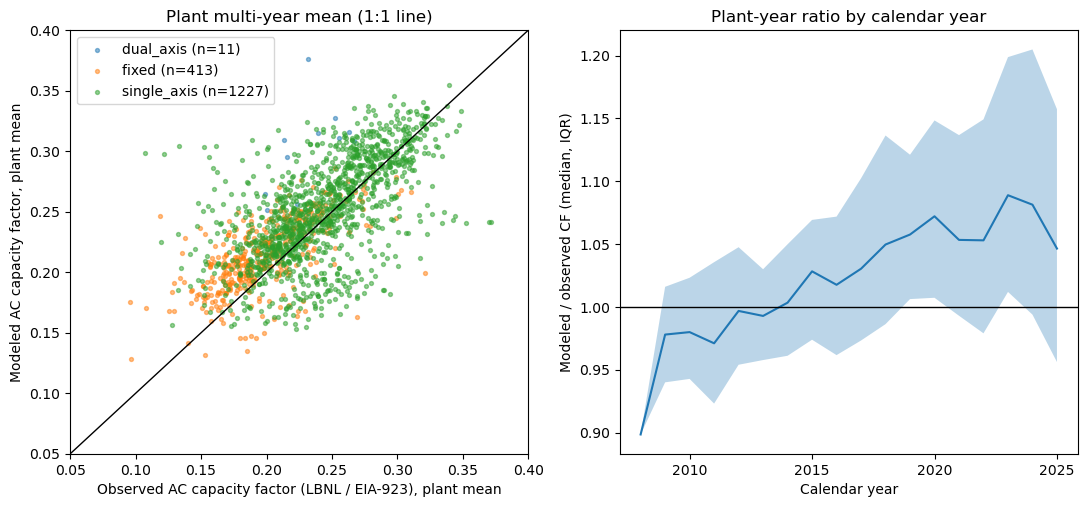

Exported: S:\Users\stidjaco\R_files\BigPanel\Data\Derived\intermediateProducts\GMSEUS_Generation_Validation_LBNL_pvgis.csv


In [49]:
import requests
import matplotlib.pyplot as plt
import figureTheme as ft # shared figure theme (utils/figureTheme.py)
ft.apply()

# Validation settings
validCapTol = 0.2 # drop plants whose GM-SEUS AC capacity differs from LBNL's by more than this fraction

# Download the LBNL data file if missing (~63 MB)
if not os.path.exists(lbnlPath):
    os.makedirs(os.path.dirname(lbnlPath), exist_ok=True)
    with requests.get(lbnlUrl, stream=True, timeout=300, headers={'User-Agent': 'Mozilla/5.0 (research data download script)'}) as r:
        r.raise_for_status()
        with open(lbnlPath, 'wb') as f:
            for chunk in r.iter_content(chunk_size=8 * 1024 * 1024): f.write(chunk)

# Call LBNL plant data (PV only), with yearly capacity factor columns ('2008 Capacity Factor', ...)
lbnl = pd.read_excel(lbnlPath, sheet_name='Individual_Project_Data')
lbnl = lbnl[lbnl['Solar Tech Main'] == 'PV'].copy()
lbnl['eiaID'] = pd.to_numeric(lbnl['EIA ID'], errors='coerce')
lbnl = lbnl.dropna(subset=['eiaID']).drop_duplicates('eiaID')
cfCols = [c for c in lbnl.columns if str(c).endswith('Capacity Factor')]

# Link USPVDB-sourced arrays to EIA plant IDs (GM-SEUS nativeID = USPVDB case_id)
uspvdbIDs = gpd.read_file(uspvdbPath, ignore_geometry=True)[['case_id', 'eia_id']].apply(pd.to_numeric, errors='coerce').rename(columns={'eia_id': 'eiaID'})
arrayLink = gpd.read_file(gmseusArraysPath, ignore_geometry=True, columns=[arrayIDcol, 'nativeID', 'Source'])
arrayLink = arrayLink[arrayLink['Source'] == 'USPVDB'].assign(case_id=lambda d: pd.to_numeric(d['nativeID'], errors='coerce'))
arrayLink = arrayLink.merge(uspvdbIDs, on='case_id', how='left')

# Modeled generation and AC capacity (from this run's exported outputs)
genLongV = pd.read_csv(genLong_path)
genInputsV = pd.read_csv(genInputs_path, usecols=[arrayIDcol, 'pvMount', 'pvCapMWAC'])
arrayLink = arrayLink.merge(genInputsV, on=arrayIDcol, how='inner')
arrayLink = arrayLink[arrayLink['eiaID'].isin(lbnl['eiaID'])]
print('USPVDB-sourced arrays matched to an LBNL plant:', len(arrayLink), '| plants:', arrayLink['eiaID'].nunique())

# Modeled plant-year capacity factor; keep years when all of a plant's arrays operate
plantGen = genLongV.merge(arrayLink[[arrayIDcol, 'eiaID', 'pvCapMWAC', 'pvMount']], on=arrayIDcol)
plantYr = plantGen.groupby(['eiaID', 'calYr']).agg(MWh=('MWh', 'sum'), capMWAC=('pvCapMWAC', 'sum'), nArrays=(arrayIDcol, 'nunique'), pvMount=('pvMount', 'first')).reset_index()
plantYr = plantYr[plantYr['nArrays'] == plantYr['eiaID'].map(arrayLink.groupby('eiaID')[arrayIDcol].nunique())]
plantYr['cfModel'] = plantYr['MWh'] / (plantYr['capMWAC'] * 8760)

# Observed plant-year capacity factor (full years after commercial operation only)
obs = lbnl.melt(id_vars=['eiaID', 'Project Name', 'Solar COD Year', 'Solar Capacity MW-AC', 'Region', 'State'], value_vars=cfCols, var_name='cfYear', value_name='cfObs').dropna(subset=['cfObs'])
obs['calYr'] = obs['cfYear'].str[:4].astype(int)
obs = obs[obs['calYr'] > obs['Solar COD Year']]

# Join, and drop plants whose capacity does not match LBNL's
genValid = plantYr.merge(obs.drop(columns='cfYear'), on=['eiaID', 'calYr'])
genValid['capRatio'] = genValid['capMWAC'] / genValid['Solar Capacity MW-AC']
print('Plants dropped for capacity mismatch (>', validCapTol, '):', genValid.loc[(genValid['capRatio'] - 1).abs() > validCapTol, 'eiaID'].nunique())
genValid = genValid[(genValid['capRatio'] - 1).abs() <= validCapTol]
genValid['ratio'] = genValid['cfModel'] / genValid['cfObs']

# ~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~ Summary statistics

# Plant multi-year means (primary comparison)
plantMean = genValid.groupby('eiaID').agg(cfModel=('cfModel', 'mean'), cfObs=('cfObs', 'mean'), nYearsObs=('calYr', 'size'), capMWAC=('capMWAC', 'first'), pvMount=('pvMount', 'first'), region=('Region', 'first'))
plantMean['err'] = plantMean['cfModel'] - plantMean['cfObs']
def summarize(d): return pd.Series({'plants': len(d), 'medianRatio': (d['cfModel'] / d['cfObs']).median(), 'bias': d['err'].mean(), 'MAE': d['err'].abs().mean()})
print('Plant-years:', len(genValid), '| plants:', len(plantMean))
print('Plant mean CF: bias', round(plantMean['err'].mean(), 4), '| MAE', round(plantMean['err'].abs().mean(), 4), '| r', round(plantMean['cfModel'].corr(plantMean['cfObs']), 3), '| median model/observed', round((plantMean['cfModel'] / plantMean['cfObs']).median(), 3))
print('Total modeled / observed energy (matched plant-years):', round(genValid['MWh'].sum() / (genValid['cfObs'] * genValid['capMWAC'] * 8760).sum(), 3))
print('Plant-year model/observed ratio P10/P50/P90:', genValid['ratio'].quantile([0.1, 0.5, 0.9]).round(3).tolist())
print(plantMean.groupby('pvMount').apply(summarize).round(3).to_string())
print(plantMean.groupby('region').apply(summarize).round(3).to_string())
print('Median model/observed by calendar year:', genValid.groupby('calYr')['ratio'].median().round(3).to_dict())

# ~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~ Plot and export

# a: plant multi-year mean, modeled vs observed, by mount; b: plant-year ratio by calendar year (median and middle 50%)
fig, axes = plt.subplots(1, 2, figsize=(ft.figWidth['double'], 72 * ft.mm), gridspec_kw={'wspace': 0.32})
ax = axes[0]
for m in ['fixed', 'single_axis', 'dual_axis']:
    d = plantMean[plantMean['pvMount'] == m]
    ax.scatter(d['cfObs'], d['cfModel'], s=5, alpha=0.9 if m == 'fixed' else 0.75, color=ft.mountColors[m], edgecolor=ft.textGrey if m == 'fixed' else 'none', lw=0.2,
               label=ft.mountLabels[m] + ' (n = ' + format(len(d), ',') + ')', zorder=2)
lim = [0.08, 0.40]
ax.plot(lim, lim, color=ft.ink, lw=0.7, zorder=3, label='1:1 line')
ax.set_xlim(lim); ax.set_ylim(lim); ax.set_aspect('equal')
ax.set_xlabel('Observed AC capacity factor (LBNL / EIA-923)'); ax.set_ylabel('Modeled AC capacity factor')
ax.legend(loc='upper left', fontsize=6, markerscale=2, title='Plant multi-year mean', title_fontsize=6, alignment='left')
ft.panelLabel(ax, 'a', x=-0.2)
ax = axes[1]
yearRatio = genValid.groupby('calYr')['ratio'].quantile([0.25, 0.5, 0.75]).unstack()
ax.fill_between(yearRatio.index, yearRatio[0.25], yearRatio[0.75], color=ft.versionColors['MarginalLR'], alpha=0.2, lw=0, label='Middle 50% of plants')
ax.plot(yearRatio.index, yearRatio[0.5], color=ft.versionColors['MarginalSR'], lw=1.1, marker='o', ms=2.2, label='Median plant')
ax.axhline(1, color=ft.ink, lw=0.6, ls=(0, (3, 2)), label='Perfect agreement')
ax.set_xlabel('Calendar year'); ax.set_ylabel('Modeled \u00f7 observed capacity factor')
ax.xaxis.get_major_locator().set_params(integer=True)
ax.legend(loc='upper left', fontsize=6)
ft.panelLabel(ax, 'b', x=-0.2)
ft.saveFig(fig, figure_path, 'genValidation_LBNL_' + weatherSource)
plt.show()

genValid.to_csv(genValid_path, index=False)
print('Exported:', genValid_path)